<a href="https://colab.research.google.com/github/swatisinha-AI-ml-learner/machine-learning-zoomcamp-homework/blob/main/Week_37_Graded_Mini_Project_Sinha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!pip install importlib_resources
!rm -rf /root/tensorflow_datasets/cats_vs_dogs

In [1]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras import layers


In [2]:
# 1. Load and split into train / test
(ds_train, ds_test), ds_info = tfds.load(
    'cats_vs_dogs',
    split=['train[:90%]', 'train[90%:]'],
    shuffle_files=True,
    as_supervised=True,
    with_info=True
)

BATCH_SIZE = 64

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.AHN1UA_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.


2. Preprocessing
o Resize all images to 64×64 pixels
o Normalize pixel values to the [-1, 1] range
o Cast labels to integer format
o Create training batches with labels

In [3]:
def preprocess(image, label):
  image = tf.image.resize(image,(64,64))
  image = tf.cast(image, tf.float32)
  image = (image / 127.5) - 1
  label = tf.cast(label, tf.int32)
  return image, label

In [4]:
train_ds = (ds_train
            .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
            .shuffle(1000)
            .batch(BATCH_SIZE, drop_remainder=True)
            .prefetch(tf.data.AUTOTUNE))

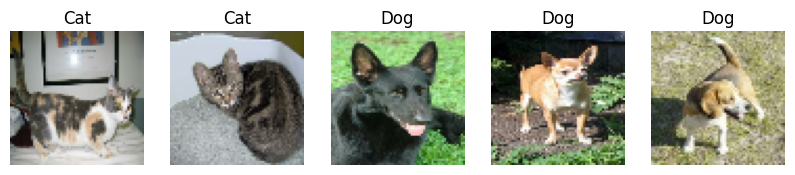

(64, 64, 64, 3) (64,)
min: -1.0 max: 1.0


In [5]:
images, labels = next(iter(train_ds))
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow((images[i] + 1) / 2)          # back to [0, 1] only for display
    plt.title("Dog" if labels[i] == 1 else "Cat")
    plt.axis("off")
plt.show()

print(images.shape, labels.shape)
print("min:", images.numpy().min(), "max:", images.numpy().max())

The generator takes noise and a label, and gives back one 64×64×3 image.

Embedding and concatenate: label to 50 numbers, then joined with 100 noise numbers, giving 150.

Dense, then Reshape: turn those 150 numbers into a small 4×4 “image” with 256 channels. This is the starting point for growing.

Four Conv2DTranspose layers: each one doubles the size: 4 to 8 to 16 to 32 to 64. The last one has 3 channels (red, green, blue).

tanh at the end: it forces every output between -1 and 1, the same scale as your real images. This is why we scaled the real pixels to [-1, 1].

In [6]:
from tensorflow.keras import layers
from tensorflow.keras import Model

output shape: (4, 64, 64, 3)
min: -0.039116222 max: 0.030277371


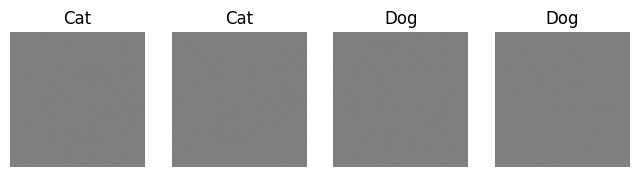

In [7]:
NOISE_DIM = 100

def build_generator():
  from tensorflow.keras import layers, Model

NOISE_DIM = 100

def build_generator():
    # Two inputs: noise and label
    noise_in = layers.Input(shape=(NOISE_DIM,))
    label_in = layers.Input(shape=(1,), dtype="int32")

    # Label -> embedding (50 numbers), then join with noise
    emb = layers.Embedding(2, 50)(label_in)      # shape (batch, 1, 50)
    emb = layers.Flatten()(emb)                  # shape (batch, 50)
    x = layers.Concatenate()([noise_in, emb])    # shape (batch, 150)

    # Dense + Reshape: make a small 4x4 starting "image"
    x = layers.Dense(4 * 4 * 256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Reshape((4, 4, 256))(x)

    # Grow: 4 -> 8 -> 16 -> 32
    for filters in [128, 64, 32]:
        x = layers.Conv2DTranspose(filters, 4, strides=2, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.LeakyReLU(0.2)(x)

    # Last layer: 32 -> 64, with 3 colors, values in [-1, 1]
    out = layers.Conv2DTranspose(3, 4, strides=2, padding="same", activation="tanh")(x)

    return Model([noise_in, label_in], out, name="generator")

generator = build_generator()

# Test it BEFORE training: 4 images, labels cat, cat, dog, dog
noise = tf.random.normal((4, NOISE_DIM))
labels = tf.constant([[0], [0], [1], [1]])
fake = generator([noise, labels], training=False)

print("output shape:", fake.shape)
print("min:", fake.numpy().min(), "max:", fake.numpy().max())

plt.figure(figsize=(8, 2))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow((fake[i] + 1) / 2)
    plt.title("Dog" if labels[i][0] == 1 else "Cat")
    plt.axis("off")
plt.show()

output means the generator is built correctly and has learned nothing yet.

The discriminator takes an image and a label, and gives back one number: how real the image looks.

The steps:

Embed the label into a “label image”: the image is 64×64, so the label embedding must also have 64×64 = 4096 numbers. Reshape those into a 64×64×1 picture.

Concatenate with the image: 64×64×3 joined with 64×64×1 gives 64×64×4. The label is now an extra channel on the image.

Conv2D layers with stride 2: each one halves the size: 64 to 32 to 16 to 8 to 4. The image shrinks while the patterns get richer.

Flatten, then Dense(1): one final number per image.

This is the opposite of the generator. The generator joins the label to noise and grows. The discriminator joins the label to the image and shrinks.

No sigmoid at the end.

The output is a raw score. A high number means “real” and a low number means “fake”.

In the loss piece, we use binary cross-entropy with from_logits=True, which handles that part.

In [8]:
def build_discriminator():
    # Two inputs: image and label
    img_in = layers.Input(shape=(64, 64, 3))
    label_in = layers.Input(shape=(1,), dtype="int32")

    # Label -> embedding (4096 numbers) -> reshape to a 64x64x1 "label image"
    emb = layers.Embedding(2, 64 * 64)(label_in)   # (batch, 1, 4096)
    emb = layers.Flatten()(emb)                    # (batch, 4096)
    emb = layers.Reshape((64, 64, 1))(emb)         # (batch, 64, 64, 1)

    # Join label image to the real/fake image: 3 + 1 = 4 channels
    x = layers.Concatenate(axis=-1)([img_in, emb])  # (batch, 64, 64, 4)

    # Shrink: 64 -> 32 -> 16 -> 8 -> 4
    for filters in [64, 128, 256, 256]:
        x = layers.Conv2D(filters, 4, strides=2, padding="same")(x)
        x = layers.LeakyReLU(0.2)(x)
        x = layers.Dropout(0.3)(x)

    # One score per image (no sigmoid)
    x = layers.Flatten()(x)
    out = layers.Dense(1)(x)

    return Model([img_in, label_in], out, name="discriminator")

discriminator = build_discriminator()

# Test it BEFORE training: 4 real images and 4 fake images
real_images = images[:4]                            # from piece 1
real_labels = tf.expand_dims(labels[:4], 1)         # shape (4, 1)

real_scores = discriminator([real_images, real_labels], training=False)
fake_scores = discriminator([fake, tf.constant([[0], [0], [1], [1]])], training=False)

print("score shape:", real_scores.shape)
print("real scores:", real_scores.numpy().flatten())
print("fake scores:", fake_scores.numpy().flatten())

score shape: (4, 1)
real scores: [ 0.0408725   0.02643724 -0.02304693  0.07743005]
fake scores: [ 0.00102606  0.00075927 -0.0001655   0.00012805]


In [9]:
# Binary cross-entropy. from_logits=True because the discriminator has no sigmoid.
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_scores, fake_scores):
    real_loss = cross_entropy(tf.ones_like(real_scores), real_scores)    # real -> 1
    fake_loss = cross_entropy(tf.zeros_like(fake_scores), fake_scores)   # fake -> 0
    return real_loss + fake_loss

def generator_loss(fake_scores):
    # The generator wants its fakes to be called real (1)
    return cross_entropy(tf.ones_like(fake_scores), fake_scores)

# One Adam optimizer for each network
generator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

@tf.function
def train_step(real_images, real_labels):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal((batch_size, NOISE_DIM))
    fake_labels = tf.random.uniform((batch_size, 1), minval=0, maxval=2, dtype=tf.int32)
    real_labels = tf.expand_dims(real_labels, 1)     # shape (batch,) -> (batch, 1)

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        fake_images = generator([noise, fake_labels], training=True)
        real_scores = discriminator([real_images, real_labels], training=True)
        fake_scores = discriminator([fake_images, fake_labels], training=True)

        g_loss = generator_loss(fake_scores)
        d_loss = discriminator_loss(real_scores, fake_scores)

    g_grads = gen_tape.gradient(g_loss, generator.trainable_variables)
    d_grads = disc_tape.gradient(d_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(g_grads, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(d_grads, discriminator.trainable_variables))
    return g_loss, d_loss


images, labels = next(iter(train_ds))
g_loss, d_loss = train_step(images, labels)
print("generator loss:", g_loss.numpy())
print("discriminator loss:", d_loss.numpy())

generator loss: 0.6808666
discriminator loss: 1.3842661


Epoch 1/10 | generator loss: 3.738 | discriminator loss: 0.280 | time: 25s


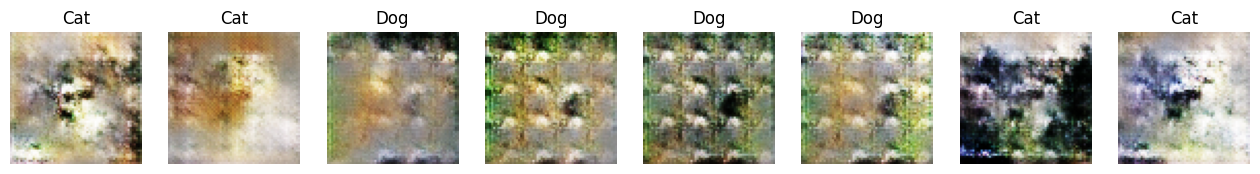

Epoch 2/10 | generator loss: 3.641 | discriminator loss: 0.286 | time: 26s
Epoch 3/10 | generator loss: 3.647 | discriminator loss: 0.299 | time: 25s
Epoch 4/10 | generator loss: 3.683 | discriminator loss: 0.274 | time: 25s
Epoch 5/10 | generator loss: 3.710 | discriminator loss: 0.289 | time: 25s


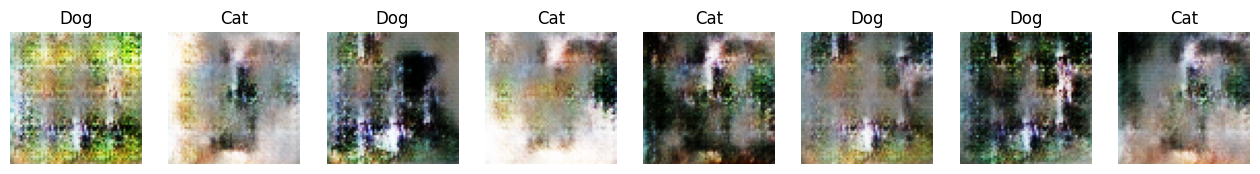

Epoch 6/10 | generator loss: 3.913 | discriminator loss: 0.262 | time: 25s
Epoch 7/10 | generator loss: 3.737 | discriminator loss: 0.271 | time: 25s
Epoch 8/10 | generator loss: 3.861 | discriminator loss: 0.243 | time: 25s
Epoch 9/10 | generator loss: 3.773 | discriminator loss: 0.262 | time: 25s
Epoch 10/10 | generator loss: 3.878 | discriminator loss: 0.246 | time: 25s


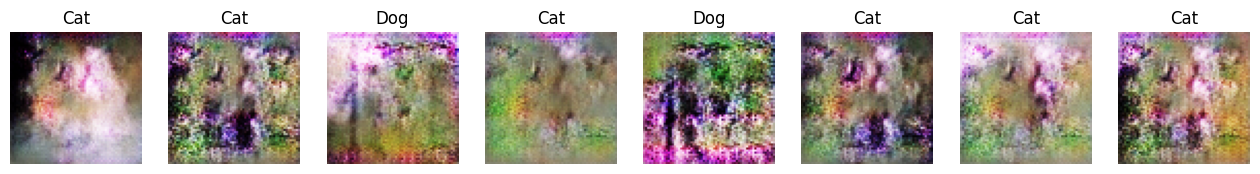

In [13]:
import time

EPOCHS = 10

def show_images(n=8):
    # Random labels: 0 = cat, 1 = dog
    noise = tf.random.normal((n, NOISE_DIM))
    rand_labels = tf.random.uniform((n, 1), minval=0, maxval=2, dtype=tf.int32)
    fake = generator([noise, rand_labels], training=False)
    fake = (fake + 1) / 2                      # back to [0, 1] for display

    plt.figure(figsize=(2 * n, 2.4))
    for i in range(n):
        plt.subplot(1, n, i + 1)
        plt.imshow(fake[i])
        plt.title("Dog" if rand_labels[i][0] == 1 else "Cat")
        plt.axis("off")
    plt.show()

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    g_losses, d_losses = [], []

    for batch_images, batch_labels in train_ds:
        g_loss, d_loss = train_step(batch_images, batch_labels)
        g_losses.append(g_loss.numpy())
        d_losses.append(d_loss.numpy())

    print(f"Epoch {epoch}/{EPOCHS} | "
          f"generator loss: {np.mean(g_losses):.3f} | "
          f"discriminator loss: {np.mean(d_losses):.3f} | "
          f"time: {time.time() - start:.0f}s")

    if epoch in (1, 5, 10):                    # peek at the progress
        show_images()

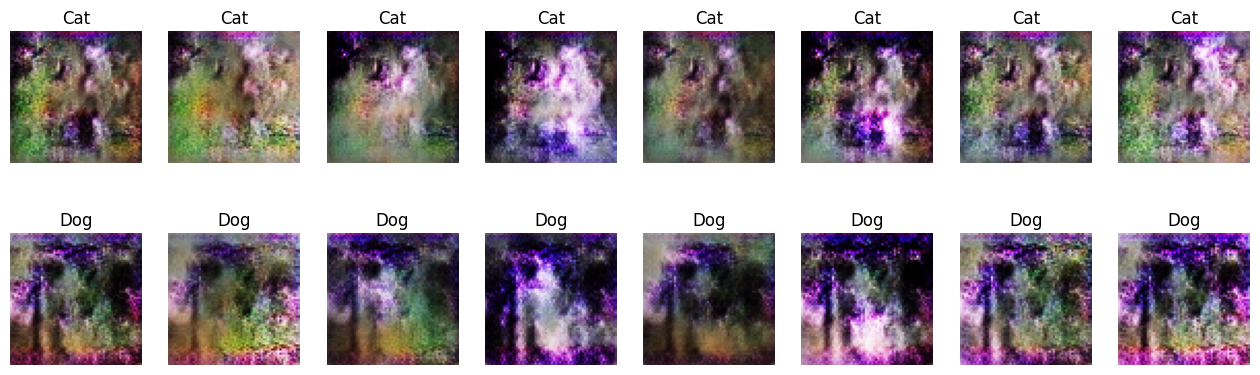

In [14]:
n = 8
noise = tf.random.normal((n, NOISE_DIM))
cat_labels = tf.zeros((n, 1), dtype=tf.int32)
dog_labels = tf.ones((n, 1), dtype=tf.int32)

cats = (generator([noise, cat_labels], training=False) + 1) / 2
dogs = (generator([noise, dog_labels], training=False) + 1) / 2

plt.figure(figsize=(2 * n, 4.8))
for i in range(n):
    plt.subplot(2, n, i + 1)
    plt.imshow(cats[i]); plt.title("Cat"); plt.axis("off")
    plt.subplot(2, n, n + i + 1)
    plt.imshow(dogs[i]); plt.title("Dog"); plt.axis("off")
plt.show()